<div style="display: flex; background-color: RGB(255,114,0);" >
<h2 style="margin: auto; padding: 30px; ">Projet 1: Classification de Faux/Vrai Billets</h2>
</div>

<div style="display: flex;" >
<h3 style="margin: auto; padding: 30px; ">CONTEXTE</h3>
<p>L’un des objectifs de la BEAC (Banque des Etats de l’Afrique Centrale) est de mettre en place des méthodes d’identification des contrefaçons des billets en Francs CFA. Dans le cadre de cette lutte, il souhaite mettre en place un algorithme qui soit capable de différencier automatiquement les vrais des faux billets.</p>
</div>

<div style="display: flex;" >
<h3 style="margin: auto; padding: 30px; ">OBJECTIFS</h3>
<p>Lorsqu’un billet arrive, la BEAC a une machine qui consigne l’ensemble de ses caractéristiques géométriques. Au travers des années de lutte, il a observé des différences de dimensions entre les vrais et les faux billets. Ces différences sont difficilement notables à l’œil nu, mais une machine devrait sans problème arriver à les différencier. 
Ainsi, il faudrait construire un algorithme qui, à partir des caractéristiques géométriques d’un billet, serait capable de définir si ce dernier est un vrai ou un faux billet.</p>
</div>

<div style="display: flex;" >
<h3 style="margin: auto; padding: 30px; ">MISSION</h3>
<p>Vous êtes expert data scientist et vous êtes recruté en CDD pour trouver une solution à ce problème en utilisant l’approche d’apprentissage automatique. Le langage de programmation utilisé est Python.</p>
</div>

In [1]:
# importer les librairie
import pandas as pd

In [2]:
df = pd.read_csv("billets.csv", sep=";")

## I- Annalyse pre-exploratoire

In [3]:
print("Nombre de lignes:", df.shape[0])
print("Nombre de colonnes:", df.shape[1])

Nombre de lignes: 1500
Nombre de colonnes: 7


In [4]:
nbLn, nbCl = df.shape
print("Nombre de lignes:", nbLn)
print("Nombre de colonnes:", nbCl)

Nombre de lignes: 1500
Nombre de colonnes: 7


In [5]:
df.head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [6]:
df.columns

Index(['is_genuine', 'diagonal', 'height_left', 'height_right', 'margin_low',
       'margin_up', 'length'],
      dtype='object')

In [7]:
df.tail()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
1495,False,171.75,104.38,104.17,4.42,3.09,111.28
1496,False,172.19,104.63,104.44,5.27,3.37,110.97
1497,False,171.80,104.01,104.12,5.51,3.36,111.95
1498,False,172.06,104.28,104.06,5.17,3.46,112.25
1499,False,171.47,104.15,103.82,4.63,3.37,112.07


In [8]:
df

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54
...,...,...,...,...,...,...,...
1495,False,171.75,104.38,104.17,4.42,3.09,111.28
1496,False,172.19,104.63,104.44,5.27,3.37,110.97
1497,False,171.80,104.01,104.12,5.51,3.36,111.95
1498,False,172.06,104.28,104.06,5.17,3.46,112.25


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagonal,1500.0,171.958440,0.305195,171.04,171.750,171.96,172.17,173.01
height_left,1500.0,104.029533,0.299462,103.14,103.820,104.04,104.23,104.88
height_right,1500.0,103.920307,0.325627,102.82,103.710,103.92,104.15,104.95
margin_low,1463.0,4.485967,0.663813,2.98,4.015,4.31,4.87,6.90
margin_up,1500.0,3.151473,0.231813,2.27,2.990,3.14,3.31,3.91
length,1500.0,112.678500,0.872730,109.49,112.030,112.96,113.34,114.44


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB


In [11]:
df.astype('object').describe().T

,count,unique,top,freq
is_genuine,1500,2,True,1000
diagonal,1500.0,159.0,171.99,28.0
height_left,1500.0,155.0,103.95,30.0
height_right,1500.0,170.0,103.76,28.0
margin_low,1463.0,285.0,4.08,20.0
margin_up,1500.0,123.0,3.08,35.0
length,1500.0,336.0,113.38,19.0


In [12]:
df.isnull().sum()

is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

In [13]:
df["margin_low_med"] = df["margin_low"].fillna(df["margin_low"].median())

In [14]:
df.dropna().isnull().info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1463 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   is_genuine      1463 non-null   bool 
 1   diagonal        1463 non-null   bool 
 2   height_left     1463 non-null   bool 
 3   height_right    1463 non-null   bool 
 4   margin_low      1463 non-null   bool 
 5   margin_up       1463 non-null   bool 
 6   length          1463 non-null   bool 
 7   margin_low_med  1463 non-null   bool 
dtypes: bool(8)
memory usage: 22.9 KB


In [15]:
df.isnull().sum()

is_genuine         0
diagonal           0
height_left        0
height_right       0
margin_low        37
margin_up          0
length             0
margin_low_med     0
dtype: int64

In [16]:
df = df.drop(columns=['margin_low_med'])
df.head(1)

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83


In [17]:
df_test = df[df['margin_low'].isnull()]
#df_train = df[~df['margin_low'].isnull()]
df_train = df.dropna()

In [18]:
X_train = df_train.drop(columns=['margin_low', 'is_genuine'])
y_train = df_train['margin_low']

In [19]:
X_train.head()

,diagonal,height_left,height_right,margin_up,length
0,171.81,104.86,104.95,2.89,112.83
1,171.46,103.36,103.66,2.99,113.09
2,172.69,104.48,103.50,2.94,113.16
3,171.36,103.91,103.94,3.01,113.51
4,171.73,104.28,103.46,3.48,112.54


In [20]:
y_train.head()

0    4.52
1    3.77
2    4.40
3    3.62
4    4.04
Name: margin_low, dtype: float64

In [21]:
df_test.head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
72,True,171.94,103.89,103.45,NaN,3.25,112.79
99,True,171.93,104.07,104.18,NaN,3.14,113.08
151,True,172.07,103.80,104.38,NaN,3.02,112.93
197,True,171.45,103.66,103.80,NaN,3.62,113.27
241,True,171.83,104.14,104.06,NaN,3.02,112.36


In [22]:
from sklearn.linear_model import LinearRegression

In [23]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [24]:
X_test = df_test.drop(columns=['margin_low', 'is_genuine'])
y_pred = lr_model.predict(X_test)
y_pred.shape

(37,)

In [25]:
y_pred

array([4.31852466, 4.39366755, 4.41045663, 4.31901423, 4.6506171 ,
       3.80330831, 4.17973608, 4.12744154, 4.13503418, 4.16053851,
       4.17742026, 3.76855378, 4.05876385, 4.29804709, 4.16060746,
       4.09406453, 4.43984627, 4.47065037, 4.34164322, 4.08041448,
       3.61430588, 4.37181147, 4.09362068, 4.24962896, 3.89374829,
       3.74633265, 4.23741481, 4.71053287, 4.13778022, 5.05027715,
       4.80214523, 5.067584  , 5.04756967, 4.77896717, 5.726993  ,
       5.18586214, 5.14004269])

In [26]:
df.loc[df.margin_low.isnull(), "margin_low"] = y_pred

In [27]:
df.isnull().sum()

is_genuine      0
diagonal        0
height_left     0
height_right    0
margin_low      0
margin_up       0
length          0
dtype: int64

In [28]:
lr_model.coef_

array([-0.11105978,  0.18412242,  0.25713805,  0.2561879 , -0.40910293])

In [29]:
df.duplicated().sum()

0

## Analyse Exploratoire

### Uni-variée

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

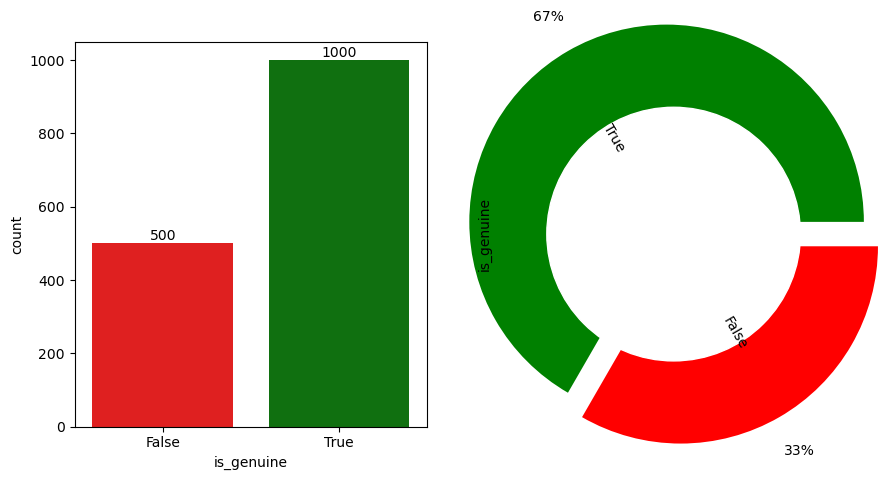

In [31]:
palette = ['red', 'green']
plt.figure(figsize=(10, 5))
plt.subplot(121)
ax = sns.countplot(data=df, x="is_genuine", palette=palette)
for container in ax.containers:
    ax.bar_label(container)
    
plt.subplot(122)
df["is_genuine"].value_counts().plot(kind="pie",
                                    colors=["green", "red"],
                                    autopct='%1.0f%%', radius=1.4,
                                    explode = (0.1, 0.1),
                                    pctdistance=1.2,
                                    labeldistance=0.4,
                                    rotatelabels=True)
# plt.subplot(133)
circle = plt.Circle((0, 0), 0.9, color = 'white')
plt.gcf().gca().add_artist(circle)
plt.show()

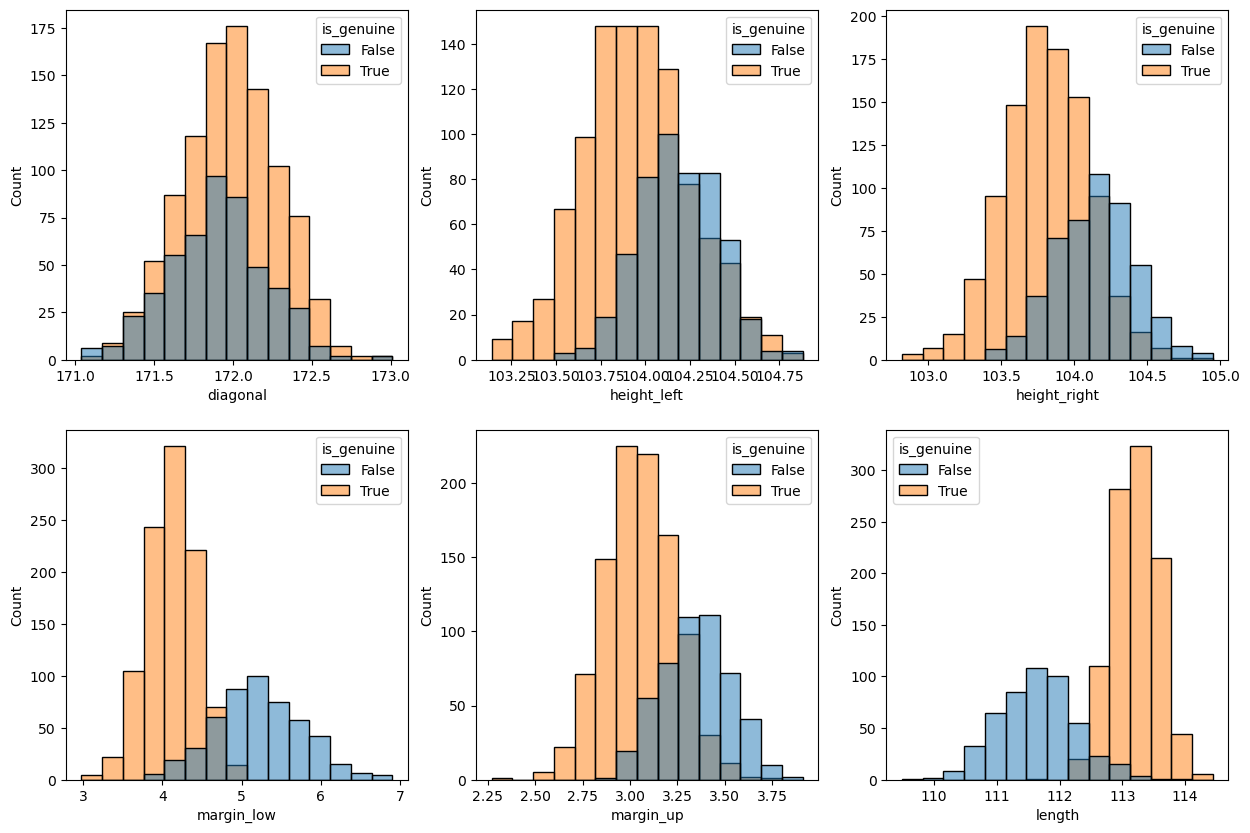

In [32]:
columns = ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for idx, col in enumerate(columns): 
    plt.subplot(2,3, idx+1)
    sns.histplot(data=df, x=col, bins=15, hue="is_genuine")

plt.show()

### Bi - Variée

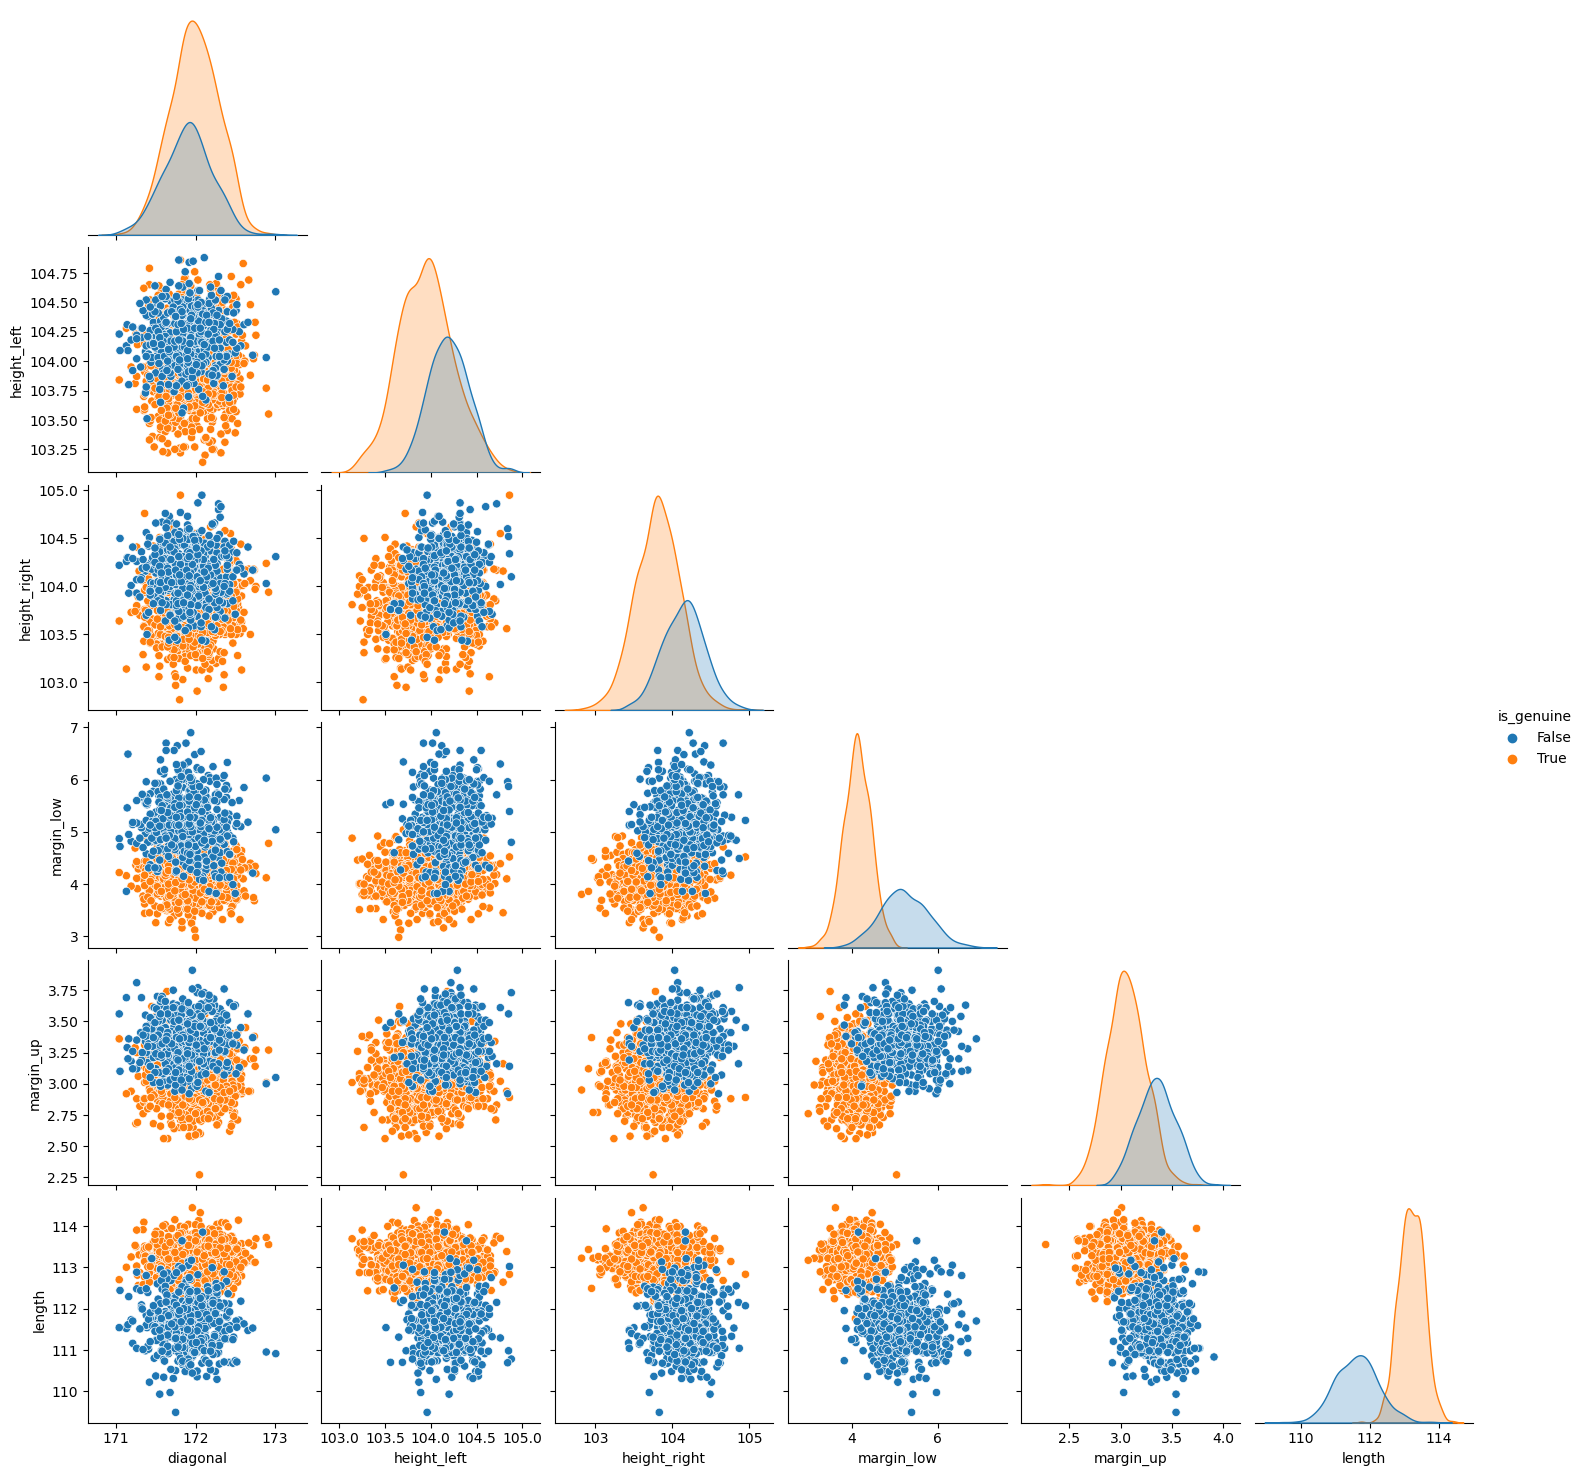

In [33]:
sns.pairplot(df, hue="is_genuine", corner=True)

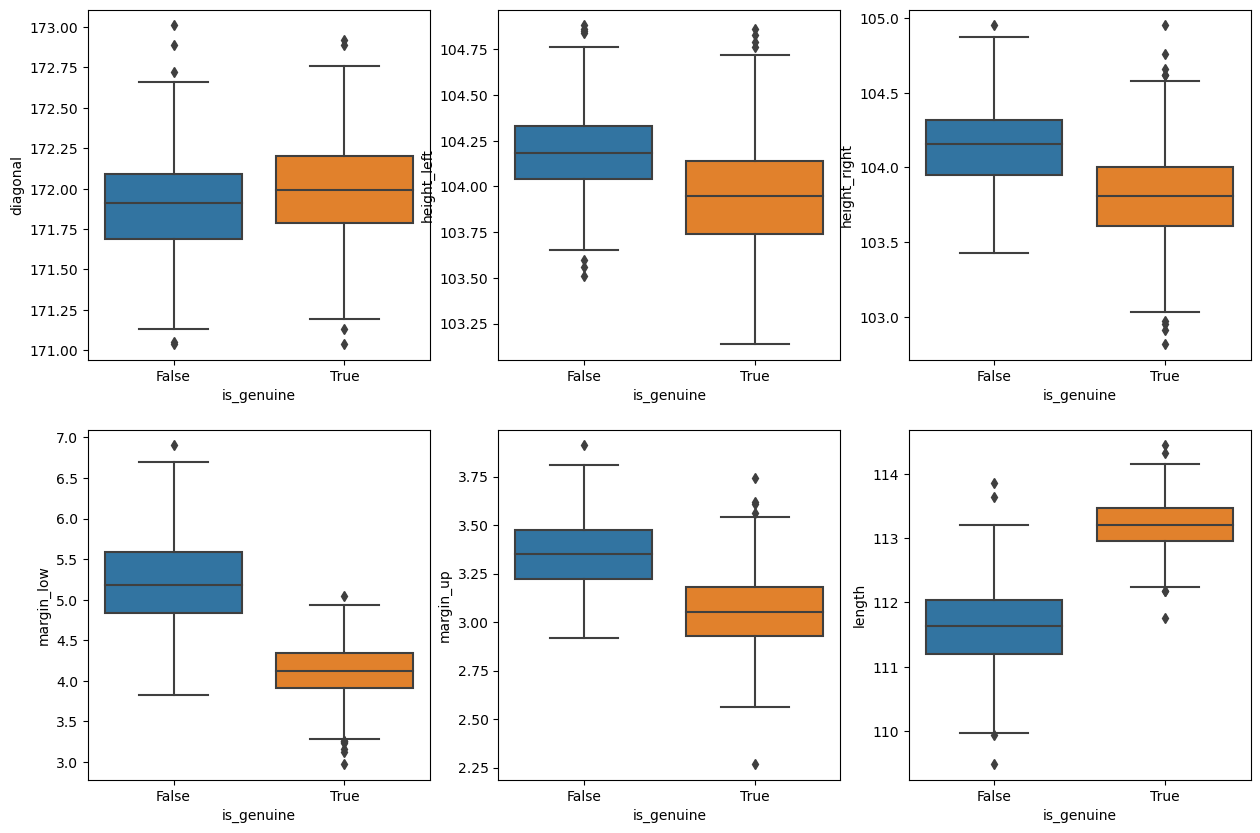

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for idx, col in enumerate(columns): 
    plt.subplot(2,3, idx+1)
    sns.boxplot(data=df, y=col, x="is_genuine")

plt.show()

<Figure size 1000x800 with 0 Axes>

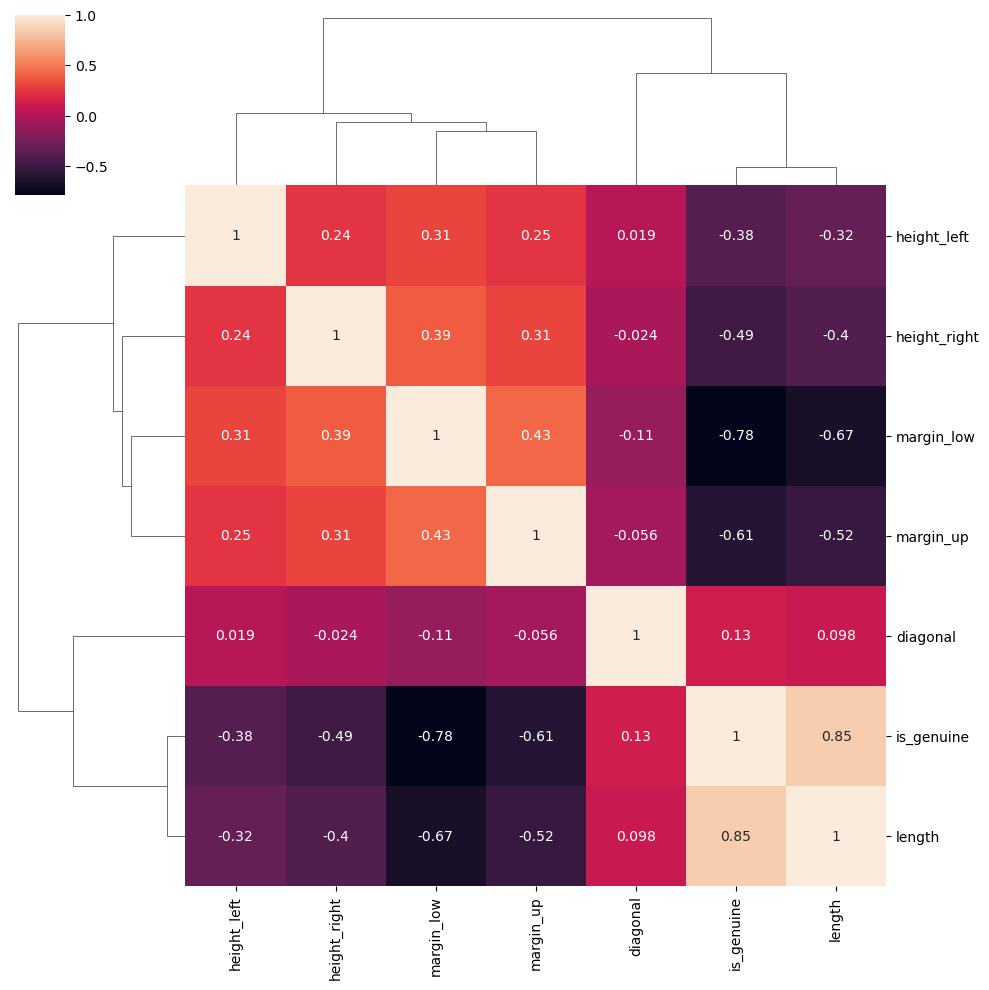

In [35]:
plt.figure(figsize=(10, 8))
sns.clustermap(df.corr(), annot=True)
plt.show()

In [36]:
df.corr()[df.corr()>0.8]

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
is_genuine,1.000000,NaN,NaN,NaN,NaN,NaN,0.849285
diagonal,NaN,1.0,NaN,NaN,NaN,NaN,NaN
height_left,NaN,NaN,1.0,NaN,NaN,NaN,NaN
height_right,NaN,NaN,NaN,1.0,NaN,NaN,NaN
margin_low,NaN,NaN,NaN,NaN,1.0,NaN,NaN
margin_up,NaN,NaN,NaN,NaN,NaN,1.0,NaN
length,0.849285,NaN,NaN,NaN,NaN,NaN,1.000000


In [37]:
### Multi - variée

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [39]:
df_ = df.drop(columns=['is_genuine']).values
df_scaled = StandardScaler().fit_transform(df_)

In [40]:
pca = PCA(n_components = 2)
pca.fit(df_scaled)

PCA(n_components=2)

In [41]:
pcs = pca.components_
print(pcs)

[[-0.08469767  0.33063448  0.39355544  0.50769282  0.4394146  -0.52705225]
 [ 0.94130387  0.30752844  0.10833184 -0.07243963 -0.00495445  0.04863598]]


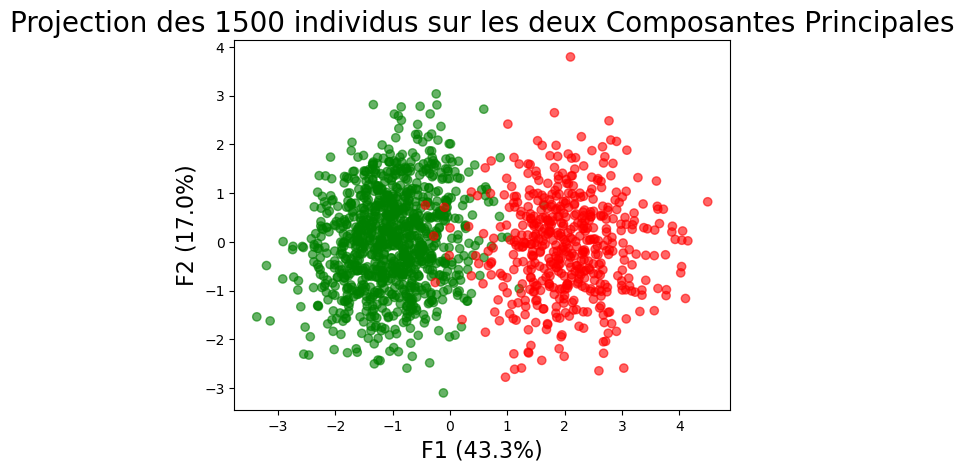

In [42]:
X_projected = pca.transform(df_scaled)

# mapping de couleurs pour  is_genuine
cmap = {True: 'green', False: 'red'}
colors = [cmap[val] for val in df["is_genuine"].values]

plt.scatter(X_projected[:, 0], X_projected[:, 1], c = colors, alpha=0.6)

plt.xlabel('F{} ({}%)'.format(1, round(100*pca.explained_variance_ratio_[0], 1)), fontsize=16)
plt.ylabel('F{} ({}%)'.format(2, round(100*pca.explained_variance_ratio_[1], 1)), fontsize=16)
plt.title("Projection des {} individus sur les deux Composantes Principales".format(X_projected.shape[0]), fontsize=20)
plt.show()

## Modelisation

In [43]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, precision_score, f1_score,recall_score,confusion_matrix
from sklearn.model_selection import GridSearchCV

In [44]:
X = df.drop(columns=['is_genuine']).values
y = df['is_genuine'].values

In [45]:
scaler = StandardScaler()
X_scaler = scaler.fit_transform(X) 

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X_scaler, y, test_size=0.25, random_state=67)

In [47]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [48]:
def performance(y_test, y_pred):
    prediction_metrics = [accuracy_score, 
                          precision_score, 
                          recall_score, 
                          f1_score]
    results = []
    results += [m(y_test, y_pred) for m in prediction_metrics]

    dict_resultats = {
        "accuracy_score":[results[0]],
        "precision_score":[results[1]],
        "recall_score":[results[2]],
        "f1_score":[results[3]]
    }

    return pd.DataFrame.from_dict(dict_resultats)

In [49]:
y_pred = model.predict(X_test)

In [50]:
performance(y_test, y_pred)

,accuracy_score,precision_score,recall_score,f1_score
0,0.989333,0.991968,0.991968,0.991968


In [51]:
classification_rep = classification_report(y_test, y_pred)
print("Rapport de classification :")
print(classification_rep)

Rapport de classification :
              precision    recall  f1-score   support

       False       0.98      0.98      0.98       126
        True       0.99      0.99      0.99       249

    accuracy                           0.99       375
   macro avg       0.99      0.99      0.99       375
weighted avg       0.99      0.99      0.99       375



Text(0.5, 1.0, 'Matrice de confusion des classe')

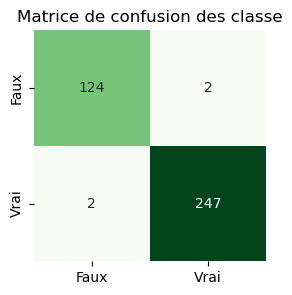

In [52]:
cnf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(3,3))
sns.heatmap(data=cnf_matrix, annot=True, cmap="Greens",fmt=".0f", cbar=False, xticklabels=['Faux', 'Vrai'], yticklabels=['Faux', 'Vrai'])
plt.title('Matrice de confusion des classe')

## Optimization

In [53]:
pipeline = Pipeline(steps = [
    ('scaler', StandardScaler()),  # Étape de mise à l'échelle des données
    ('cls', LogisticRegression())  # Étape du modèle de classification
])

In [54]:
hyperparameters = {
    'cls__C': [1, 1.35, 1.75],
    'cls__solver': ['newton-cg', 'lbfgs', 'liblinear'],
    'cls__penalty': ['l1', 'l2','elasticnet', 'none']
}

In [59]:
lgr_model = GridSearchCV(pipeline, 
                         hyperparameters,
                         cv=5)
lgr_model.fit(X_train, y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1173: FutureWarning: `penalty='none'`has been deprecated in 1.2 and will be removed in 1.4. To keep the past behaviour, set `penalty=None`.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1173: FutureWarning: `penalty='none'`has been deprecated in 1.2 and will be removed in 1.4. To keep the past behaviour, set `penalty=None`.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1173: FutureWarning: `penalty='none'`has been deprecated in 1.2 and will be removed in 1.4. To keep the past behaviour, set `penalty=None`.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1173: FutureWarning: `penalty='none'`has been deprecated in 1.2 and will be removed in 1.4. To keep the past behaviour, set `penalty=None`.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('cls', LogisticRegression())]),
             param_grid={'cls__C': [1, 1.35, 1.75],
                         'cls__penalty': ['l1', 'l2', 'elasticnet', 'none'],
                         'cls__solver': ['newton-cg', 'lbfgs', 'liblinear']})

In [60]:
print("Meilleurs hyper paramètres :", lgr_model.best_params_)

Meilleurs hyper paramètres : {'cls__C': 1, 'cls__penalty': 'l2', 'cls__solver': 'newton-cg'}


In [61]:
lgr_model.best_score_

0.9893333333333333

In [62]:
y_pred = lgr_model.predict(X_test)
performance(y_test, y_pred)

,accuracy_score,precision_score,recall_score,f1_score
0,0.989333,0.991968,0.991968,0.991968


In [67]:
print(lgr_model.best_estimator_["cls"].coef_)
print("columns: ", list(df.drop(columns=['is_genuine']).columns))

[[ 0.16565912 -0.57297282 -0.77507638 -2.39462685 -1.80791914  3.55012158]]
columns:  ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']


In [68]:
import pickle
# nom du modele
filename = 'best_model.pkl'

# sauvegardons le modele avec pickle
with open(filename, 'wb') as file:
    pickle.dump(lgr_model.best_estimator_, file)